# Fatal Incidents, Accidents and Violence in Nigeria: Data Analysis Project

**Dataset:** *Incidents, Accidents and Violence in Nigeria* (Kaggle, `incidents_updated.csv`)
**Tools:** Python, pandas, NumPy, Matplotlib, Seaborn

Each row in the dataset is one reported fatal incident, with an identifier, a title (event and location), start and end dates, and the number of deaths. This notebook cleans the data, explores it, and turns the patterns into findings and recommendations.

**Contents**
1. Research questions
2. Data preparation and cleaning
3. Exploratory data analysis (EDA)
4. Charts and graphs
5. Findings and recommendations

## 1. Research Questions

1. **Where?** Which states and geopolitical zones record the most fatal incidents and the most deaths, and which are the deadliest *per incident*?
2. **What?** Which types of incident (road accidents, banditry, insurgency, floods and so on) account for the most deaths?
3. **When?** How have incidents and deaths changed over time, and is there a seasonal pattern?
4. **How concentrated?** How much of the total death toll comes from a small number of mass-casualty events?
5. **North vs South:** How do the north and south differ in the *kind* of fatal incidents they experience?

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from difflib import get_close_matches

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titleweight"] = "bold"
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

## 2. Data Preparation and Cleaning

The cleaning steps are: inspect the raw data, rename columns, handle duplicates, fix dates, split the title into *event* and *location*, standardise state names, group events into categories, and engineer features. Every decision is explained so it can be defended.

### 2.1 Load and inspect the raw data

In [2]:
raw = pd.read_csv("incidents_updated.csv")
print("Shape (rows, columns):", raw.shape)
raw.head(10)

Shape (rows, columns): (10978, 5)


,Identifier,Title,Start date,End date,Number of deaths
0,IBD031681,"Food Poisoning, Imo",2025-04-18,2025-04-18,1
1,IBD032064,"Gunmen Kill Man, Benue",2025-03-31,2025-03-31,1
2,IBD032058,"Auto Crash, Lagos",2025-03-31,2025-03-31,1
3,IBD032066,"Stray Bullets, Sokoto",2025-03-31,2025-03-31,1
4,IBD032062,"Lightening Kills Herder, Kaduna",2025-03-30,2025-03-30,1
5,IBD032049,"Auto Crash, Katsina",2025-03-30,2025-03-30,9
6,IBD032065,"Sallah Day Celebration Clash, Plateau",2025-03-30,2025-03-30,4
7,IBD032054,"Auto Crash, Abia",2025-03-30,2025-03-30,1
8,IBD032048,"Gas Explosion, Delta",2025-03-30,2025-03-30,2
9,IBD032061,"Auto Crash, Ogun",2025-03-30,2025-03-30,1


In [3]:
raw.info()
print("\nMissing values per column:")
print(raw.isna().sum())

<class 'pandas.DataFrame'>
RangeIndex: 10978 entries, 0 to 10977
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Identifier        10978 non-null  str  
 1   Title             10978 non-null  str  
 2   Start date        10978 non-null  str  
 3   End date          10978 non-null  str  
 4   Number of deaths  10978 non-null  int64
dtypes: int64(1), str(4)
memory usage: 429.0 KB

Missing values per column:
Identifier          0
Title               0
Start date          0
End date            0
Number of deaths    0
dtype: int64


In [4]:
raw.describe()

,Number of deaths
count,"10,978.00"
mean,4.87
std,12.48
min,1.00
25%,1.00
50%,1.00
75%,4.00
max,440.00


**What the inspection shows**
- 10,978 rows and 5 columns, with **no missing values**.
- There is **no state column and no incident-type column**. Both are hidden inside `Title` (for example *"Auto Crash, Lagos"*), so they have to be extracted.
- `Number of deaths` starts at 1, so this is a **fatality dataset**: every row has at least one death.
- Deaths are heavily skewed (median 1, mean about 4.9, max 440), so medians must be reported alongside totals.

### 2.2 Rename columns

In [5]:
df = raw.copy()
df.columns = ["id", "title", "start", "end", "deaths"]
df.head(3)

,id,title,start,end,deaths
0,IBD031681,"Food Poisoning, Imo",2025-04-18,2025-04-18,1
1,IBD032064,"Gunmen Kill Man, Benue",2025-03-31,2025-03-31,1
2,IBD032058,"Auto Crash, Lagos",2025-03-31,2025-03-31,1


### 2.3 Duplicates

Check two things: rows that are *exactly* identical, and rows that merely share an `Identifier`.

In [6]:
print("Exact duplicate rows:", df.duplicated().sum())
print("Rows with a repeated Identifier:", df["id"].duplicated().sum())

# Identifiers that are shared by rows which are NOT exact duplicates
non_exact = df.drop_duplicates()
shared_id = non_exact[non_exact["id"].duplicated(keep=False)].sort_values("id")
print("\nRows sharing an Identifier but with different content:", len(shared_id))
shared_id

Exact duplicate rows: 210
Rows with a repeated Identifier: 218

Rows sharing an Identifier but with different content: 16


,id,title,start,end,deaths
0,IBD031681,"Food Poisoning, Imo",2025-04-18,2025-04-18,1
10603,IBD031681,"Food Poisoning, Imo",2025-04-18,2025-04-18,2
170,IBD031890,"Boko Harm Kill Police Officer Children, Borno",2025-03-03,2025-03-03,2
10934,IBD031890,"Boko Harm Kill Police Officer Children, Yobe",2025-03-03,2025-03-03,2
187,IBD031913,"Female Corpses, Delta",2025-03-01,2025-03-01,2
10951,IBD031913,"Ritual Killing, Delta",2025-03-01,2025-03-01,2
96,IBD031950,"Army vs Bandits, Katsina",2025-03-15,2025-03-15,12
10679,IBD031950,"Banditry, Katsina",2025-04-08,2025-04-08,10
351,IBD031962,"Domestic Violence, Akwa Ibom",2025-02-06,2025-02-06,1
7863,IBD031962,"Deputy Governor's Aide, Niger",2026-05-21,2026-05-21,1


**Decision:** drop only **exact duplicate rows** (210). The few rows that share an `Identifier` but describe different events (different title, location or date) are genuinely different incidents, so they are kept. Deduplicating on `Identifier` alone would delete real events.

In [7]:
before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Rows before: {before:,} | after: {len(df):,} | removed: {before - len(df)}")

Rows before: 10,978 | after: 10,768 | removed: 210


### 2.4 Dates

Convert both date columns to datetime and check that the end date is never before the start date.

In [8]:
for c in ["start", "end"]:
    df[c] = pd.to_datetime(df[c], errors="coerce")

print("Unparseable dates:\n", df[["start", "end"]].isna().sum())
print("Date range:", df["start"].min().date(), "to", df["start"].max().date())

reversed_dates = df["end"] < df["start"]
print("\nRows where end date is BEFORE start date:", reversed_dates.sum())
df[reversed_dates].head(14)

Unparseable dates:
 start    0
end      0
dtype: int64
Date range: 2022-06-17 to 2026-07-14

Rows where end date is BEFORE start date: 14


,id,title,start,end,deaths
2134,IBD028052,"Auto Crash, Abia",2024-05-23,2023-05-23,4
2834,IBD029365,"Kidnap Victims, Imo",2024-03-01,2024-02-01,5
3420,IBD028563,"Assailants vs Lady, Lagos",2023-12-01,2023-11-01,1
4079,IBD027910,"Troops Kill kidnappers, Plateau",2023-08-28,2023-08-04,1
4256,IBD027680,"Cult Killing, Lagos",2023-08-01,2023-07-01,1
4700,IBD027203,"Student vs Host Community, Ogun",2023-05-29,2023-05-28,1
7320,IBD024913,"Cult Killing, Lagos",2022-07-07,2022-07-01,2
7815,IBD035139,"Domestic Violence, Kano",2026-05-29,2026-05-02,1
8398,IBD034467,"Boko Haram Attack, Borno",2026-02-28,2026-02-01,12
8483,IBD034380,"Domestic Violence, Abia",2026-02-17,2026-02-16,1


**Decision:** these 14 rows (0.13% of the data) look like data-entry slips (for example, a year or a month typed wrongly), so the two dates are **swapped**. This is an assumption, and with so few rows it cannot change any conclusion.

**Coverage warning (important for the time analysis):** the data starts on **17 June 2022** and ends on **14 July 2026**, so **2022 and 2026 are partial years**. Only 2023, 2024 and 2025 are complete years and can be compared fairly.

In [9]:
df.loc[reversed_dates, ["start", "end"]] = df.loc[reversed_dates, ["end", "start"]].values
print("Reversed dates remaining:", (df["end"] < df["start"]).sum())

Reversed dates remaining: 0


### 2.5 Split `Title` into event and location

Titles follow the pattern **"Event, Location"**. `rsplit(",", n=1)` splits at the **last** comma, which matters because some events also contain commas.

In [10]:
df["title"] = df["title"].str.strip()
df["event"] = df["title"].str.rsplit(",", n=1).str[0].str.strip()
df["raw_location"] = df["title"].str.rsplit(",", n=1).str[-1].str.strip()

print("Distinct raw location values:", df["raw_location"].nunique(), "(Nigeria has 36 states + FCT = 37)")
print("\nA sample of the messy values:")
df["raw_location"].value_counts().tail(20)

Distinct raw location values: 119 (Nigeria has 36 states + FCT = 37)

A sample of the messy values:


raw_location
Katstina                              1
Kwara 2                               1
Kwara 3                               1
Kwara 1                               1
Kano 2                                1
Katisna                               1
Kebbi 1                               1
Kebbi 2                               1
Gwoza                                 1
Land Tussle                           1
Gunmen Kill Vigilante. Kwara          1
Gunmen Kill Farmers Plateau           1
ISWAP Terrorists Kill Village Head    1
Boat Mishap. Taraba                   1
Nigeria                               1
Banditry Zamfara                      1
Zamafra                               1
Guma                                  1
Delta`                                1
Badagry                               1
Name: count, dtype: int64

Nigeria has only 37 states (including the FCT), but there are over 100 distinct location strings. They contain **typos** (*Zamafara, katisna, Jiagawa*), **inconsistent capitalisation** (*kaduna, delta*), **FCT variants** (*FCT, Abuja, FCT ( Abuja), (Abuja)*), **suffixes** (*Rivers (Offshore)*, *Kwara 2*), and some rows where the comma was missing and the location is not a state at all.

### 2.6 Standardise state names

Approach, in order:
1. Strip bracketed text, "(Offshore)", digits and stray characters, and lowercase everything.
2. Exact match against the list of 36 states + FCT.
3. A small dictionary for known variants and town names (*Abuja* → FCT, *Uyo* → Akwa Ibom, *Bonny* → Rivers).
4. **Fuzzy matching** (`difflib`, cutoff 0.8) to catch remaining typos.
5. As a last resort, check whether a state name appears at the **end** of the string (for example *"Police vs Gunmen Benue"*).

Anything still unmatched is labelled **Unknown** and not guessed.

In [11]:
STATES = ["Abia", "Adamawa", "Akwa Ibom", "Anambra", "Bauchi", "Bayelsa", "Benue", "Borno", "Cross River",
          "Delta", "Ebonyi", "Edo", "Ekiti", "Enugu", "FCT", "Gombe", "Imo", "Jigawa", "Kaduna", "Kano",
          "Katsina", "Kebbi", "Kogi", "Kwara", "Lagos", "Nasarawa", "Niger", "Ogun", "Ondo", "Osun", "Oyo",
          "Plateau", "Rivers", "Sokoto", "Taraba", "Yobe", "Zamfara"]
LOWER = {s.lower(): s for s in STATES}

KNOWN_VARIANTS = {
    "abuja": "FCT", "river": "Rivers", "niger state": "Niger",
    "zamafara": "Zamfara", "zamafra": "Zamfara", "jiagawa": "Jigawa", "jigiwa": "Jigawa",
    "jigaawa": "Jigawa", "anmabra": "Anambra", "nasaraawa": "Nasarawa", "nasarwa": "Nasarawa",
    "tabara": "Taraba", "katstina": "Katsina", "katisna": "Katsina", "kadun": "Kaduna",
    "kadauna": "Kaduna", "bornon": "Borno", "uyo": "Akwa Ibom", "port harcourt": "Rivers",
    "bonny": "Rivers", "gwoza": "Borno", "guma": "Benue", "badagry": "Lagos",
}

def to_state(raw_value):
    s = re.sub(r"\(.*?\)", " ", str(raw_value))          # remove (Abuja), (Offshore)
    s = s.replace("`", "").replace("(", " ").replace(")", " ")
    s = re.sub(r"\boffshore\b", "", s, flags=re.I)
    s = re.sub(r"\b\d+\b", "", s)                         # remove trailing numbers (Kwara 2)
    s = re.sub(r"fc\s*t", "FCT", s, flags=re.I)             # FC T -> FCT
    s = re.sub(r"\s+", " ", s).strip().lower()

    if s in LOWER:                 return LOWER[s]            # 2. exact match
    if s in KNOWN_VARIANTS:        return KNOWN_VARIANTS[s]   # 3. known variants
    if s == "fct" or "abuja" in str(raw_value).lower(): return "FCT"
    close = get_close_matches(s, list(LOWER), n=1, cutoff=0.8)   # 4. fuzzy match
    if close:                      return LOWER[close[0]]
    for key in sorted(LOWER, key=len, reverse=True):         # 5. state name at the end
        if s.endswith(key):        return LOWER[key]
    return None

df["state"] = df["raw_location"].map(to_state)
print("Rows with no state found:", df["state"].isna().sum())
df.loc[df["state"].isna(), ["title"]]

Rows with no state found: 12


,title
857,"Vigilantes vs Kidnappers,"
858,Youths vs LASTMA/Police
1798,Vigilantes vs Bandits
2316,Man Shot at Fuel Station
2930,Police vs Bandit
5172,Troops vs Bandits
5345,"Master Warrant Officer, Hamza Musa"
6122,Air Force vs Bandits
6307,"Landlady vs Tenant,"
6869,"Police vs Kidnapper,"


In [12]:
df["state"] = df["state"].fillna("Unknown")
print("Distinct states after cleaning:", df["state"].nunique(), "(37 states/FCT + 'Unknown' = 38 expected)")
df["state"].value_counts().head(10)

Distinct states after cleaning: 38 (37 states/FCT + 'Unknown' = 38 expected)


state
Lagos      871
Ogun       632
Kaduna     560
Borno      545
Benue      528
FCT        476
Plateau    467
Delta      458
Niger      453
Anambra    363
Name: count, dtype: int64

Over 100 messy values are now **37 states plus "Unknown"**. Only 12 rows (about 0.1%) could not be placed. They are kept, labelled *Unknown*, and excluded from state-level charts.

### 2.7 Group events into incident categories

The event text has thousands of distinct wordings (*Auto Crash*, *Gunmen Attack*, *Soldiers vs Boko Haram* and so on). Keyword rules group them into broader categories.

**Rule order matters:** the first matching rule wins, so more specific categories are tested before broader ones.

In [13]:
CATEGORY_RULES = [
    ("Road accident",            r"auto crash|road|motor|truck|tanker|accident|bike|tricycle"),
    ("Flood / natural disaster", r"flood|lightning|lightening|heat wave|rainstorm|windstorm"),
    ("Fire / explosion",         r"inferno|fire|explosion|gas"),
    ("Building collapse",        r"collapse"),
    ("Boat / drowning",          r"boat|drown|canoe"),
    ("Electrocution",            r"electrocut"),
    ("Cult / ritual",            r"cult|ritual"),
    ("Domestic violence",        r"domestic|wife|husband"),
    ("Communal / farmer-herder", r"herd|communal|farmer|land|fulani"),
    ("Military operation",       r"army|soldier|troops|naf|airstrike|air force|security operatives|police vs|vs police"),
    ("Banditry / kidnapping",    r"bandit|kidnap|abduct"),
    ("Terrorism / insurgency",   r"boko haram|iswap|terrorist|lakurawa"),
    ("Gunmen / armed attack",    r"gunmen|assailants|attack|shot|stray bullet"),
    ("Political / mob violence", r"political|mob|protest|riot|youths"),
    ("Health / negligence",      r"medical|poison|food|cholera|lassa"),
]

def categorise(event_text):
    t = str(event_text).lower()
    for name, pattern in CATEGORY_RULES:
        if re.search(pattern, t):
            return name
    return "Other"

df["category"] = df["event"].map(categorise)
df["category"].value_counts()

category
Other                       2000
Road accident               1726
Military operation          1615
Banditry / kidnapping       1172
Gunmen / armed attack        965
Communal / farmer-herder     811
Cult / ritual                585
Domestic violence            377
Terrorism / insurgency       290
Flood / natural disaster     248
Boat / drowning              240
Political / mob violence     228
Fire / explosion             201
Building collapse            113
Electrocution                100
Health / negligence           97
Name: count, dtype: int64

In [14]:
print("Share of rows in 'Other':", f"{(df['category'] == 'Other').mean():.1%}")
print("\nMost common events left in 'Other':")
df.loc[df["category"] == "Other", "event"].value_counts().head(12)

Share of rows in 'Other': 18.6%

Most common events left in 'Other':


event
Extrajudicial Killing     29
Man vs Friend             29
Corpse Found              29
Found Dead                26
Extra-Judicial Killing    24
Mysterious Death          23
Rape Victim               21
Sex Romp                  19
Man Dies                  19
One Killed                17
Assailant vs Man          15
Witchcraft                15
Name: count, dtype: int64

**Limitations of this step (to state openly):**
- The categories are **keyword-based**, so some events can be mis-grouped. For example, *"Police vs Kidnappers"* matches the military/police rule before the kidnapping rule.
- About 19% of rows fall into **"Other"**. These are mostly vague titles (*Found Dead*, *Man vs Friend*, *Mysterious Death*) that cannot be classified from the title alone.
- The **"Military operation"** category records deaths in clashes with security forces. Many of these victims are the suspected bandits or militants who were killed, so these deaths are not all civilian.

### 2.8 Feature engineering

Add time features, incident duration, and the **geopolitical zone** (Nigeria's six zones), which gives a more meaningful regional comparison than 37 separate states.

In [15]:
ZONES = {
    "North Central": ["Benue", "FCT", "Kogi", "Kwara", "Nasarawa", "Niger", "Plateau"],
    "North East":    ["Adamawa", "Bauchi", "Borno", "Gombe", "Taraba", "Yobe"],
    "North West":    ["Jigawa", "Kaduna", "Kano", "Katsina", "Kebbi", "Sokoto", "Zamfara"],
    "South East":    ["Abia", "Anambra", "Ebonyi", "Enugu", "Imo"],
    "South South":   ["Akwa Ibom", "Bayelsa", "Cross River", "Delta", "Edo", "Rivers"],
    "South West":    ["Ekiti", "Lagos", "Ogun", "Ondo", "Osun", "Oyo"],
}
STATE_TO_ZONE = {state: zone for zone, states in ZONES.items() for state in states}

df["year"] = df["start"].dt.year
df["month"] = df["start"].dt.to_period("M").dt.to_timestamp()
df["month_num"] = df["start"].dt.month
df["weekday"] = df["start"].dt.day_name()
df["duration_days"] = (df["end"] - df["start"]).dt.days + 1
df["zone"] = df["state"].map(STATE_TO_ZONE).fillna("Unknown")
df["region"] = np.where(df["zone"].str.startswith("North"), "North",
                np.where(df["zone"].str.startswith("South"), "South", "Unknown"))
df.head()

,id,title,start,end,deaths,event,raw_location,state,category,year,month,month_num,weekday,duration_days,zone,region
0,IBD031681,"Food Poisoning, Imo",2025-04-18,2025-04-18,1,Food Poisoning,Imo,Imo,Health / negligence,2025,2025-04-01,4,Friday,1,South East,South
1,IBD032064,"Gunmen Kill Man, Benue",2025-03-31,2025-03-31,1,Gunmen Kill Man,Benue,Benue,Gunmen / armed attack,2025,2025-03-01,3,Monday,1,North Central,North
2,IBD032058,"Auto Crash, Lagos",2025-03-31,2025-03-31,1,Auto Crash,Lagos,Lagos,Road accident,2025,2025-03-01,3,Monday,1,South West,South
3,IBD032066,"Stray Bullets, Sokoto",2025-03-31,2025-03-31,1,Stray Bullets,Sokoto,Sokoto,Gunmen / armed attack,2025,2025-03-01,3,Monday,1,North West,North
4,IBD032062,"Lightening Kills Herder, Kaduna",2025-03-30,2025-03-30,1,Lightening Kills Herder,Kaduna,Kaduna,Flood / natural disaster,2025,2025-03-01,3,Sunday,1,North West,North


### 2.9 Validate and save the cleaned data

In [16]:
print("Final shape:", df.shape)
print("\nNulls in key columns:")
print(df[["id", "start", "end", "deaths", "state", "category", "zone"]].isna().sum())
assert (df["end"] >= df["start"]).all(), "some end dates are still before start dates"
assert df["deaths"].min() >= 1

df.to_csv("incidents_clean.csv", index=False)
print("\nSaved cleaned data to incidents_clean.csv")

Final shape: (10768, 16)

Nulls in key columns:
id          0
start       0
end         0
deaths      0
state       0
category    0
zone        0
dtype: int64



Saved cleaned data to incidents_clean.csv


**Cleaning summary:** 10,978 raw rows became **10,768 clean rows** (210 exact duplicates removed). Dates are valid, every row has a state (12 as *Unknown*), a category, and a zone, and the cleaned file is saved for the Streamlit app.

## 3. Exploratory Data Analysis (EDA)
### 3.1 Overall picture

In [17]:
total_deaths = df["deaths"].sum()
print(f"Fatal incidents recorded : {len(df):,}")
print(f"Total deaths             : {total_deaths:,}")
print(f"Period covered           : {df['start'].min().date()} to {df['start'].max().date()}")
print(f"Mean deaths per incident : {df['deaths'].mean():.2f}")
print(f"Median deaths per incident: {df['deaths'].median():.0f}")
print(f"Incidents with exactly 1 death: {(df['deaths'] == 1).mean():.1%}")
print(f"Incidents with 10+ deaths: {(df['deaths'] >= 10).sum():,}")
df["deaths"].describe(percentiles=[.5, .75, .9, .95, .99])

Fatal incidents recorded : 10,768
Total deaths             : 52,732
Period covered           : 2022-06-17 to 2026-07-14
Mean deaths per incident : 4.90
Median deaths per incident: 1
Incidents with exactly 1 death: 50.6%
Incidents with 10+ deaths: 1,223


count   10,768.00
mean         4.90
std         12.57
min          1.00
50%          1.00
75%          4.00
90%         10.00
95%         20.00
99%         48.00
max        440.00
Name: deaths, dtype: float64

The **mean (4.9) is nearly five times the median (1)**, which signals a very skewed distribution: most incidents kill one person, while a small number kill dozens or hundreds. Totals and averages are therefore driven by the extreme events.

### 3.2 By state

In [18]:
state_stats = (df[df["state"] != "Unknown"]
               .groupby("state")["deaths"]
               .agg(incidents="count", total_deaths="sum", median_deaths="median", mean_deaths="mean")
               .sort_values("total_deaths", ascending=False))
state_stats["share_of_deaths_%"] = state_stats["total_deaths"] / state_stats["total_deaths"].sum() * 100
state_stats.head(12)

,incidents,total_deaths,median_deaths,mean_deaths,share_of_deaths_%
state,,,,,
Borno,545,9049,8.00,16.60,17.17
Niger,453,4434,2.00,9.79,8.41
Zamfara,329,4289,5.00,13.04,8.14
Benue,528,3122,3.00,5.91,5.92
Katsina,323,3071,3.00,9.51,5.83
Kaduna,560,2966,2.00,5.30,5.63
Plateau,467,2486,2.00,5.32,4.72
Sokoto,197,1463,4.00,7.43,2.78
Lagos,871,1460,1.00,1.68,2.77


In [19]:
top5 = state_stats.head(5)
print("Top 5 states by deaths:", ", ".join(top5.index))
print(f"They account for {top5['total_deaths'].sum() / state_stats['total_deaths'].sum():.1%} of all deaths.")
print("\nMost incidents:")
print(state_stats.sort_values("incidents", ascending=False)[["incidents", "total_deaths", "mean_deaths"]].head(5))

Top 5 states by deaths: Borno, Niger, Zamfara, Benue, Katsina
They account for 45.5% of all deaths.

Most incidents:
        incidents  total_deaths  mean_deaths
state                                       
Lagos         871          1460         1.68
Ogun          632          1300         2.06
Kaduna        560          2966         5.30
Borno         545          9049        16.60
Benue         528          3122         5.91


### 3.3 By incident category

In [20]:
cat_stats = (df.groupby("category")["deaths"]
             .agg(incidents="count", total_deaths="sum", median_deaths="median", mean_deaths="mean")
             .sort_values("total_deaths", ascending=False))
cat_stats["share_of_deaths_%"] = cat_stats["total_deaths"] / cat_stats["total_deaths"].sum() * 100
cat_stats

,incidents,total_deaths,median_deaths,mean_deaths,share_of_deaths_%
category,,,,,
Military operation,1615,15432,3.00,9.56,29.26
Banditry / kidnapping,1172,7475,2.00,6.38,14.18
Road accident,1726,7068,2.00,4.10,13.40
Communal / farmer-herder,811,4744,2.00,5.85,9.00
Terrorism / insurgency,290,4029,6.00,13.89,7.64
Gunmen / armed attack,965,3353,1.00,3.47,6.36
Other,2000,3201,1.00,1.60,6.07
Flood / natural disaster,248,1871,2.00,7.54,3.55
Boat / drowning,240,1645,2.00,6.85,3.12


### 3.4 By geopolitical zone

In [21]:
zone_stats = (df[df["zone"] != "Unknown"]
              .groupby("zone")["deaths"]
              .agg(incidents="count", total_deaths="sum", median_deaths="median", mean_deaths="mean")
              .sort_values("total_deaths", ascending=False))
zone_stats["share_of_deaths_%"] = zone_stats["total_deaths"] / zone_stats["total_deaths"].sum() * 100
display(zone_stats)

region_stats = df[df["region"] != "Unknown"].groupby("region")["deaths"].agg(["count", "sum"])
region_stats["share_%"] = region_stats["sum"] / region_stats["sum"].sum() * 100
region_stats

,incidents,total_deaths,median_deaths,mean_deaths,share_of_deaths_%
zone,,,,,
North West,1976,14512,2.00,7.34,27.54
North Central,2610,13781,2.00,5.28,26.15
North East,1252,12890,3.00,10.30,24.46
South West,2307,4571,1.00,1.98,8.67
South East,1162,3554,1.00,3.06,6.74
South South,1449,3387,1.00,2.34,6.43


,count,sum,share_%
region,,,
North,5838,41183,78.15
South,4918,11512,21.85


### 3.5 Over time

Only **2023, 2024 and 2025 are complete years**. 2022 starts on 17 June and 2026 ends on 14 July, so partial years are shown separately and not compared directly.

In [22]:
yearly = df.groupby("year")["deaths"].agg(incidents="count", total_deaths="sum")
yearly["deaths_per_incident"] = yearly["total_deaths"] / yearly["incidents"]
yearly["coverage"] = ["partial (from 17 Jun)", "full", "full", "full", "partial (to 14 Jul)"]
yearly

,incidents,total_deaths,deaths_per_incident,coverage
year,,,,
2022,1653,8336,5.04,partial (from 17 Jun)
2023,2605,11893,4.57,full
2024,2609,12232,4.69,full
2025,2568,12999,5.06,full
2026,1333,7272,5.46,partial (to 14 Jul)


In [23]:
complete = df[df["year"].isin([2023, 2024, 2025])]
seasonal = complete.groupby("month_num")["deaths"].agg(incidents="count", total_deaths="sum")
seasonal.index = pd.to_datetime(seasonal.index, format="%m").strftime("%b")
seasonal

,incidents,total_deaths
month_num,,
Jan,676,3529
Feb,554,2560
Mar,690,2966
Apr,766,3681
May,685,3823
Jun,657,3935
Jul,664,2792
Aug,689,2755
Sep,670,2816


In [24]:
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
complete["weekday"].value_counts().reindex(weekday_order)

weekday
Monday       1183
Tuesday      1174
Wednesday    1059
Thursday      963
Friday        962
Saturday     1224
Sunday       1217
Name: count, dtype: int64

### 3.6 Extreme events and concentration

In [25]:
print("Ten deadliest incidents:")
display(df.nlargest(10, "deaths")[["title", "start", "deaths", "category"]].reset_index(drop=True))

mass = df[df["deaths"] >= 50]
print(f"Incidents with 50+ deaths: {len(mass)} ({len(mass) / len(df):.1%} of incidents) "
      f"-> {mass['deaths'].sum() / total_deaths:.1%} of all deaths")

top1 = df.nlargest(int(len(df) * 0.01), "deaths")
print(f"Top 1% of incidents ({len(top1)}) account for {top1['deaths'].sum() / total_deaths:.1%} of all deaths")

Ten deadliest incidents:


,title,start,deaths,category
0,"Flooding, Niger",2025-05-29,440,Flood / natural disaster
1,"Herdsmen Attack, Benue",2023-02-27,244,Communal / farmer-herder
2,"Heat Waves, Adamawa",2024-05-01,210,Flood / natural disaster
3,"Security Operatives vs Terrorists, Niger",2026-05-27,201,Military operation
4,"Banditry, Katsina",2024-03-04,200,Banditry / kidnapping
5,"ISWAP vs Boko Haram, Borno",2023-02-26,200,Terrorism / insurgency
6,"Army vs Boko Haram, Borno",2022-08-30,200,Military operation
7,"Airstrike Kill Bandits, Zamfara",2025-08-11,200,Military operation
8,"Troops Kill several Bandits, Kebbi",2025-07-09,200,Military operation
9,"Herdsmen Attack, Benue",2025-06-13,200,Communal / farmer-herder


Incidents with 50+ deaths: 101 (0.9% of incidents) -> 18.6% of all deaths
Top 1% of incidents (107) account for 19.1% of all deaths


## 4. Charts and Graphs

### 4.1 How are deaths distributed per incident?

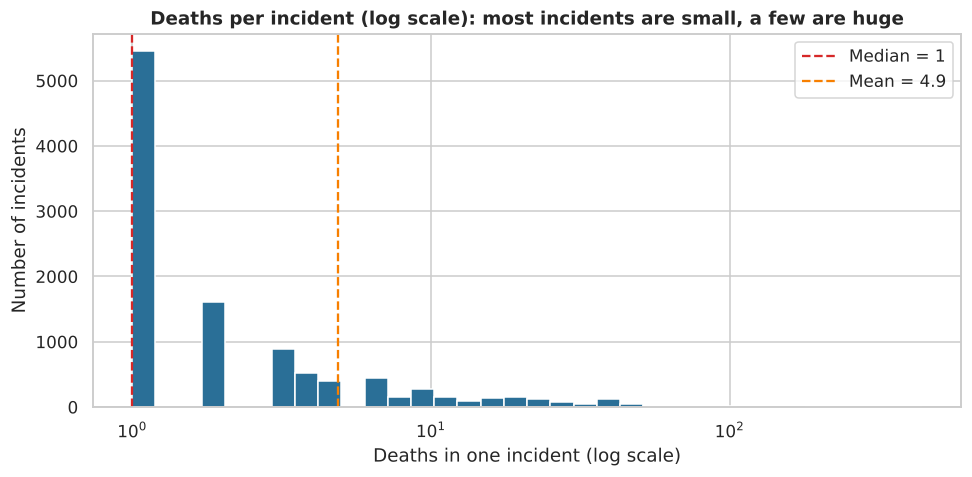

In [26]:
fig, ax = plt.subplots(figsize=(9, 4.5))
bins = np.logspace(0, np.log10(df["deaths"].max()), 35)
ax.hist(df["deaths"], bins=bins, color="#2a6f97", edgecolor="white")
ax.set_xscale("log")
ax.axvline(df["deaths"].median(), color="#d62828", ls="--", label=f"Median = {df['deaths'].median():.0f}")
ax.axvline(df["deaths"].mean(), color="#f77f00", ls="--", label=f"Mean = {df['deaths'].mean():.1f}")
ax.set_title("Deaths per incident (log scale): most incidents are small, a few are huge")
ax.set_xlabel("Deaths in one incident (log scale)")
ax.set_ylabel("Number of incidents")
ax.legend()
plt.tight_layout()
plt.show()

Half of all incidents involve a single death, but the long right tail reaches 440. This is why medians and totals are both reported in this analysis.

### 4.2 Which states record the most deaths?

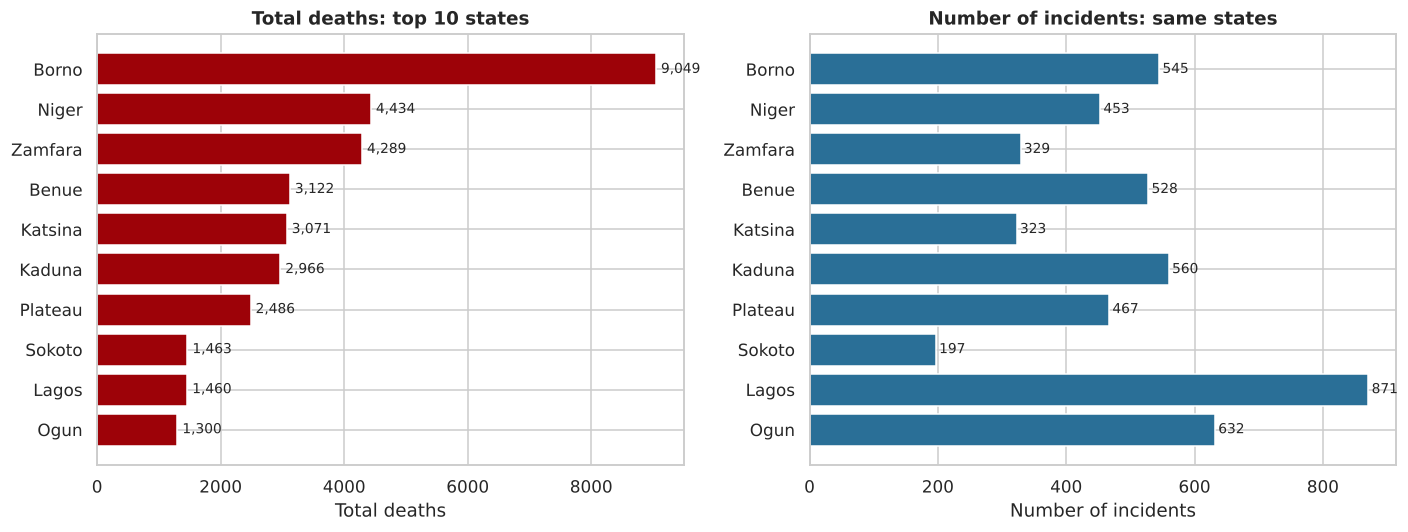

In [27]:
top10 = state_stats.head(10).iloc[::-1]
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].barh(top10.index, top10["total_deaths"], color="#9d0208")
axes[0].set_title("Total deaths: top 10 states")
axes[0].set_xlabel("Total deaths")
for i, v in enumerate(top10["total_deaths"]):
    axes[0].text(v + 80, i, f"{v:,}", va="center", fontsize=9)

axes[1].barh(top10.index, top10["incidents"], color="#2a6f97")
axes[1].set_title("Number of incidents: same states")
axes[1].set_xlabel("Number of incidents")
for i, v in enumerate(top10["incidents"]):
    axes[1].text(v + 5, i, f"{v:,}", va="center", fontsize=9)

plt.tight_layout()
plt.show()

Borno alone accounts for 9,049 deaths, far ahead of any other state, from fewer incidents than Lagos. Incident counts and death counts do not rank states in the same order.

### 4.3 Deadliest per incident (states with at least 30 incidents)

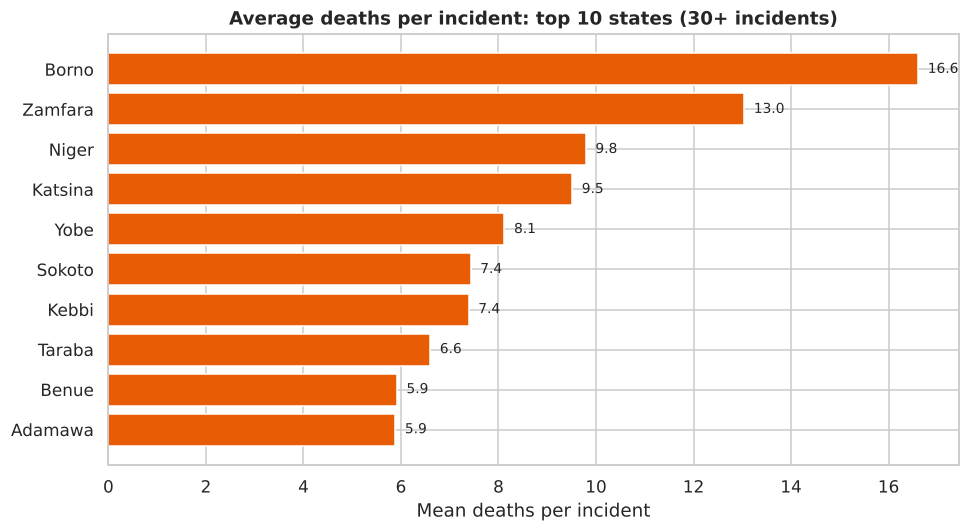

In [28]:
dpi = (state_stats[state_stats["incidents"] >= 30]
       .sort_values("mean_deaths", ascending=False).head(10).iloc[::-1])
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(dpi.index, dpi["mean_deaths"], color="#e85d04")
ax.set_title("Average deaths per incident: top 10 states (30+ incidents)")
ax.set_xlabel("Mean deaths per incident")
for i, v in enumerate(dpi["mean_deaths"]):
    ax.text(v + 0.2, i, f"{v:.1f}", va="center", fontsize=9)
plt.tight_layout()
plt.show()

Borno (16.6) and Zamfara (13.0) stand well above the rest. Lagos, by contrast, has the most incidents but only about 1.7 deaths per incident.

### 4.4 What causes the most deaths?

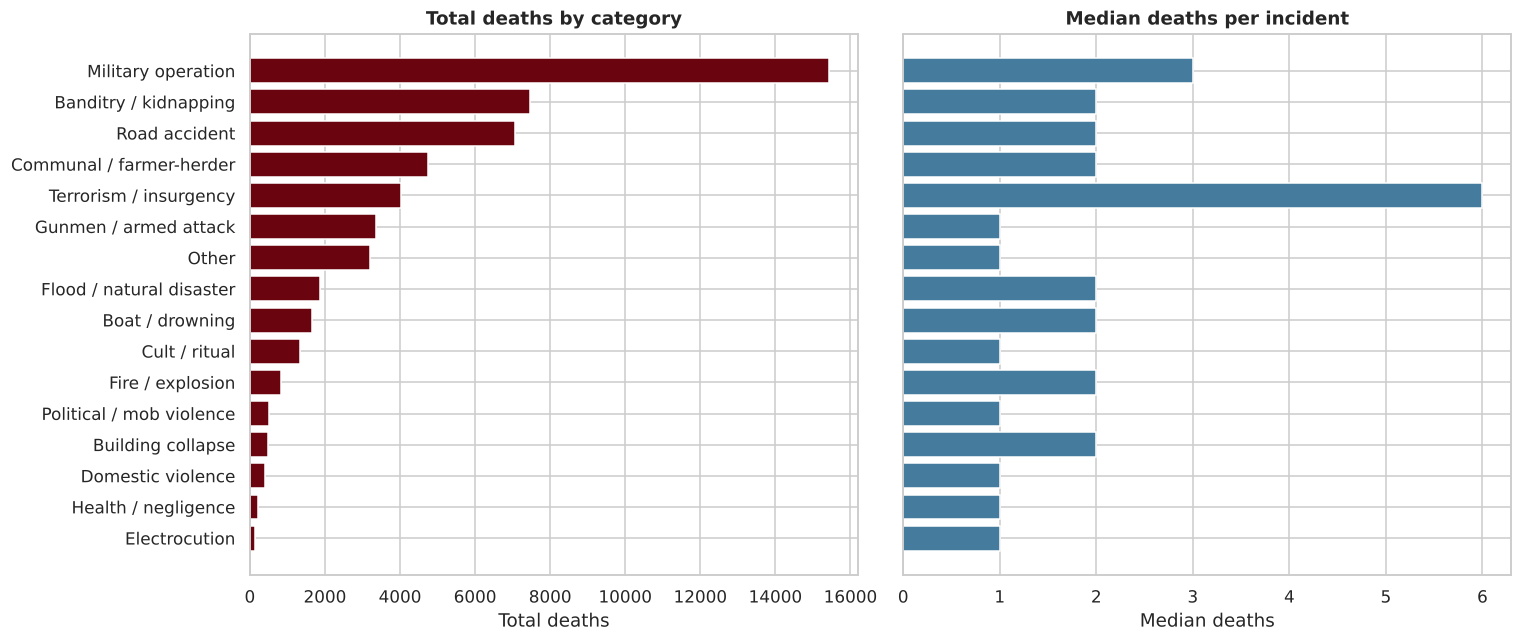

In [29]:
cs = cat_stats.sort_values("total_deaths").copy()
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)

axes[0].barh(cs.index, cs["total_deaths"], color="#6a040f")
axes[0].set_title("Total deaths by category")
axes[0].set_xlabel("Total deaths")

axes[1].barh(cs.index, cs["median_deaths"], color="#457b9d")
axes[1].set_title("Median deaths per incident")
axes[1].set_xlabel("Median deaths")

plt.tight_layout()
plt.show()

Military operations, banditry/kidnapping and road accidents lead the totals. Terrorism/insurgency has a small number of incidents but the **highest median toll (6)**, so each attack is far deadlier than a typical incident.

### 4.5 Trend over time

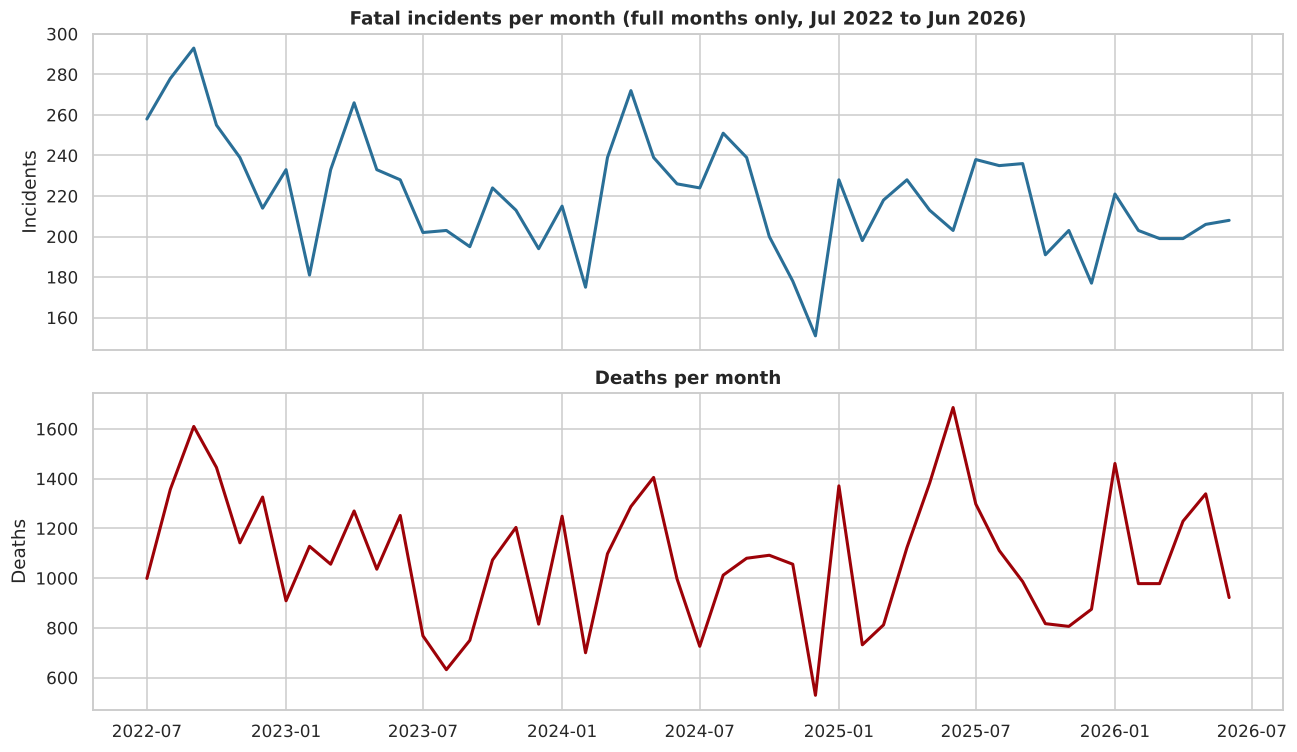

In [30]:
monthly = (df[(df["month"] > "2022-06-01") & (df["month"] < "2026-07-01")]   # full months only
           .groupby("month")["deaths"].agg(incidents="count", total_deaths="sum"))

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
axes[0].plot(monthly.index, monthly["incidents"], color="#2a6f97", lw=2)
axes[0].set_title("Fatal incidents per month (full months only, Jul 2022 to Jun 2026)")
axes[0].set_ylabel("Incidents")
axes[1].plot(monthly.index, monthly["total_deaths"], color="#9d0208", lw=2)
axes[1].set_title("Deaths per month")
axes[1].set_ylabel("Deaths")
plt.tight_layout()
plt.show()

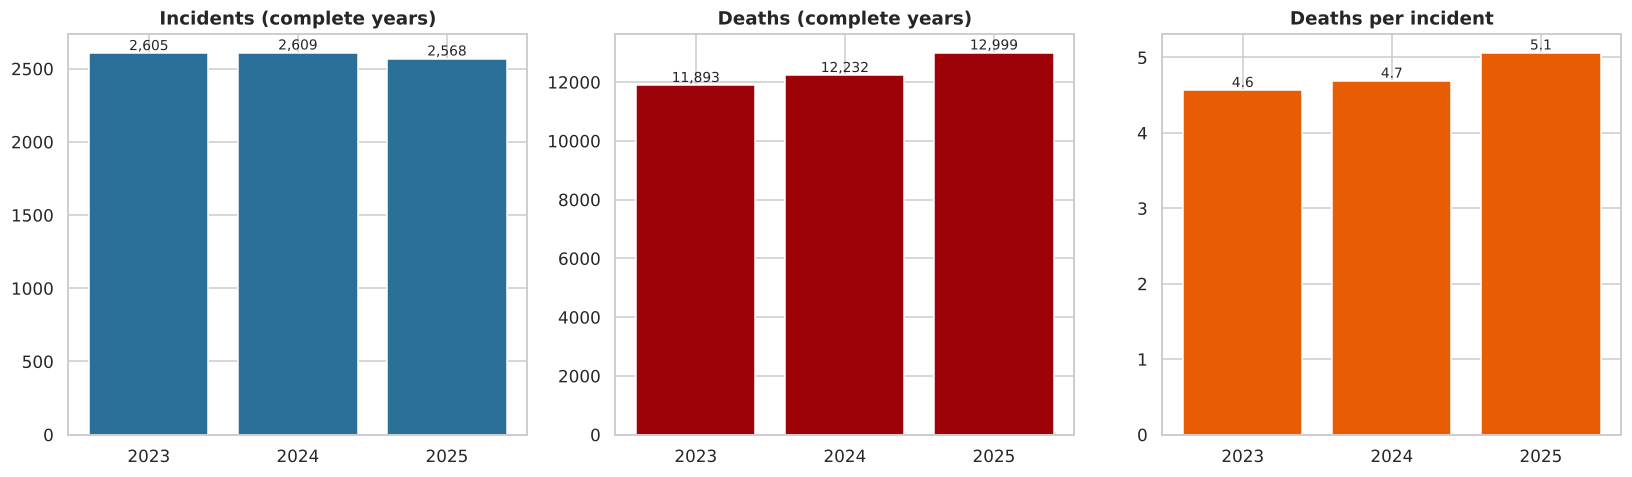

In [31]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
yy = yearly.loc[[2023, 2024, 2025]]

axes[0].bar(yy.index.astype(str), yy["incidents"], color="#2a6f97")
axes[0].set_title("Incidents (complete years)")
axes[1].bar(yy.index.astype(str), yy["total_deaths"], color="#9d0208")
axes[1].set_title("Deaths (complete years)")
axes[2].bar(yy.index.astype(str), yy["deaths_per_incident"], color="#e85d04")
axes[2].set_title("Deaths per incident")

for ax, col in zip(axes, ["incidents", "total_deaths", "deaths_per_incident"]):
    for i, v in enumerate(yy[col]):
        ax.text(i, v, f"{v:,.1f}" if col == "deaths_per_incident" else f"{v:,.0f}",
                ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.show()

Incident counts are flat across 2023 to 2025 (about 2,600 a year), but deaths rise each year (11,893 to 12,999), so the **average incident is getting deadlier**.

### 4.6 Seasonality

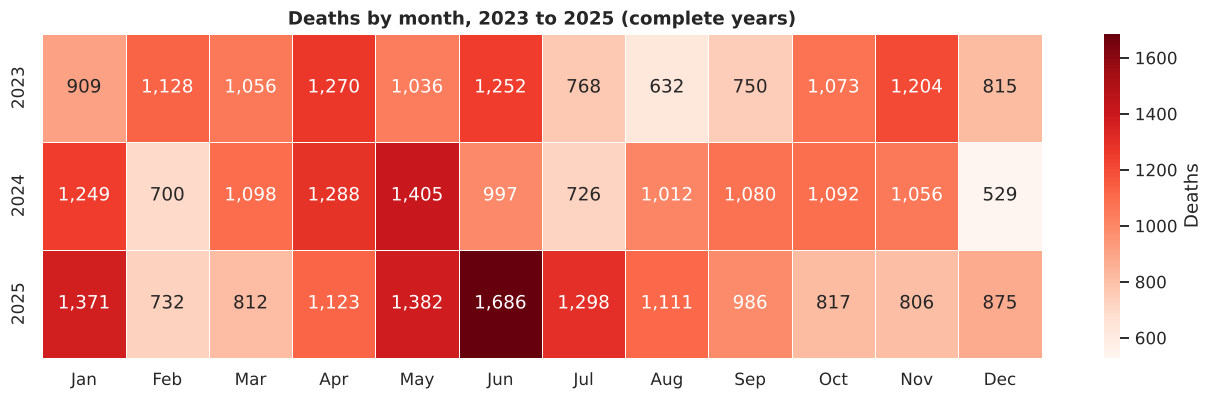

In [32]:
pivot = (complete.pivot_table(index="year", columns="month_num", values="deaths", aggfunc="sum"))
pivot.columns = pd.to_datetime(pivot.columns, format="%m").strftime("%b")

fig, ax = plt.subplots(figsize=(12, 3.8))
sns.heatmap(pivot, annot=True, fmt=",.0f", cmap="Reds", linewidths=.5, cbar_kws={"label": "Deaths"}, ax=ax)
ax.set_title("Deaths by month, 2023 to 2025 (complete years)")
ax.set_xlabel("")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

April to June is consistently the heaviest period and December the lightest. February is also low, partly because it has fewer days.

### 4.7 Day of the week

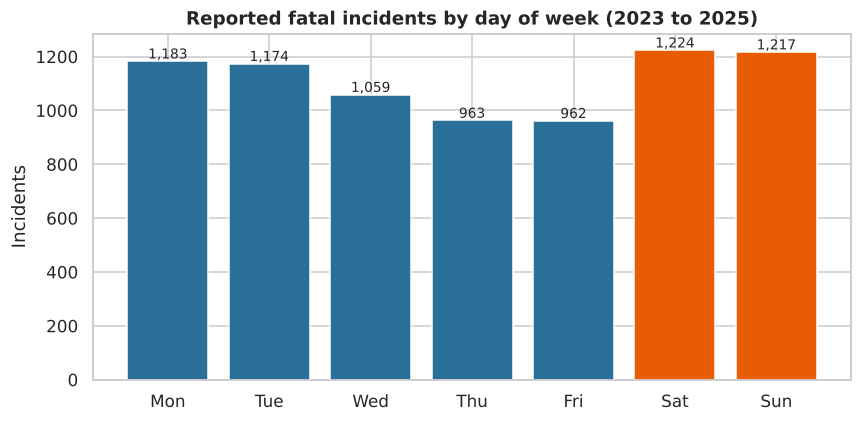

In [33]:
wd = complete["weekday"].value_counts().reindex(weekday_order)
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(wd.index.str[:3], wd.values, color=["#2a6f97"] * 5 + ["#e85d04"] * 2)
ax.set_title("Reported fatal incidents by day of week (2023 to 2025)")
ax.set_ylabel("Incidents")
for i, v in enumerate(wd.values):
    ax.text(i, v + 10, f"{v:,}", ha="center", fontsize=9)
plt.tight_layout()
plt.show()

Saturdays and Sundays record the most incidents. This could reflect real weekend risk (travel, social events, market days) or reporting patterns, and the data cannot separate the two.

### 4.8 North vs South

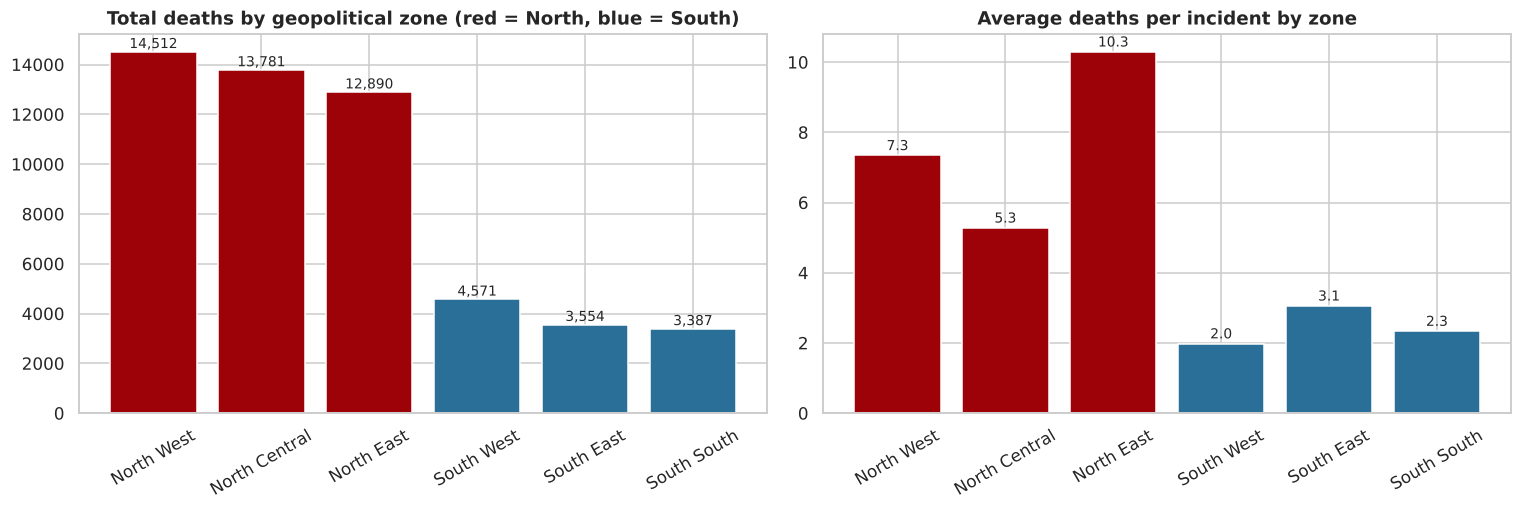

In [34]:
zs = zone_stats.sort_values("total_deaths", ascending=False)
colors = ["#9d0208" if z.startswith("North") else "#2a6f97" for z in zs.index]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
axes[0].bar(zs.index, zs["total_deaths"], color=colors)
axes[0].set_title("Total deaths by geopolitical zone (red = North, blue = South)")
axes[0].tick_params(axis="x", rotation=30)
for i, v in enumerate(zs["total_deaths"]):
    axes[0].text(i, v + 150, f"{v:,}", ha="center", fontsize=9)

axes[1].bar(zs.index, zs["mean_deaths"], color=colors)
axes[1].set_title("Average deaths per incident by zone")
axes[1].tick_params(axis="x", rotation=30)
for i, v in enumerate(zs["mean_deaths"]):
    axes[1].text(i, v + 0.15, f"{v:.1f}", ha="center", fontsize=9)

plt.tight_layout()
plt.show()

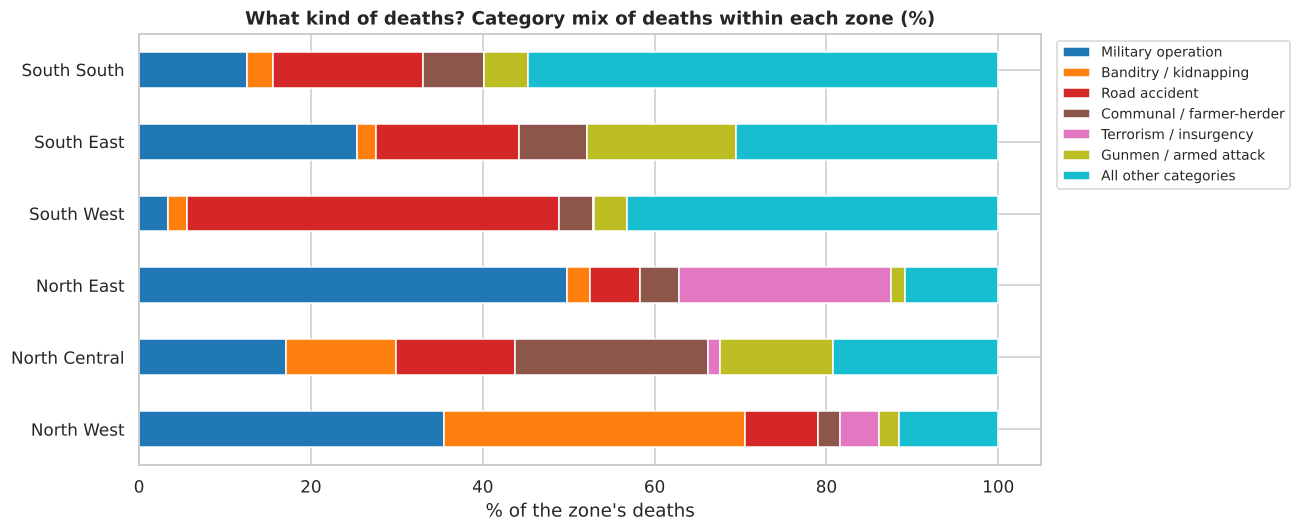

In [35]:
mix = pd.crosstab(df[df["zone"] != "Unknown"]["zone"], df[df["zone"] != "Unknown"]["category"],
                  values=df["deaths"], aggfunc="sum").fillna(0)
top_cats = cat_stats.head(6).index.tolist()
mix["All other categories"] = mix.drop(columns=top_cats).sum(axis=1)
mix = mix[top_cats + ["All other categories"]]
mix_pct = mix.div(mix.sum(axis=1), axis=0) * 100

ax = mix_pct.loc[zone_stats.index].plot(kind="barh", stacked=True, figsize=(12, 5), colormap="tab10")
ax.set_title("What kind of deaths? Category mix of deaths within each zone (%)")
ax.set_xlabel("% of the zone's deaths")
ax.set_ylabel("")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=9)
plt.tight_layout()
plt.show()

The north records about four-fifths of all deaths and is dominated by conflict-type categories (security operations, insurgency, banditry, communal violence). The **South West is the reverse**: road accidents are its largest category, and cult violence also features.

### 4.9 State by category heatmap

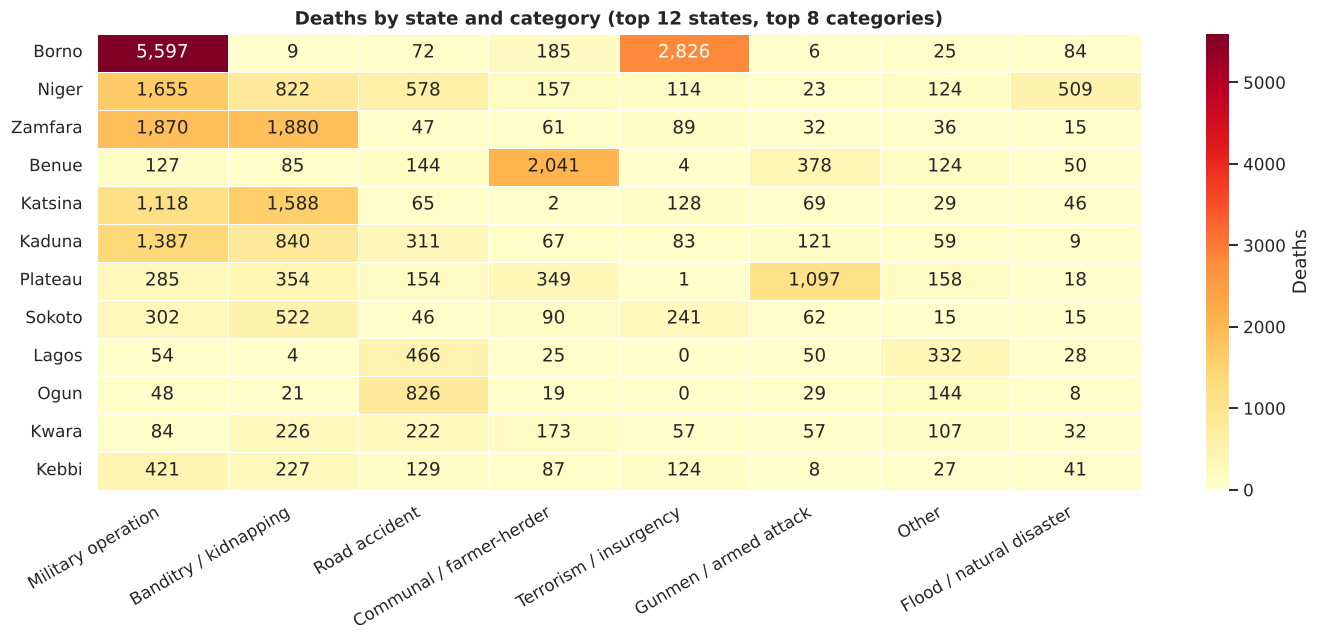

In [36]:
top_states = state_stats.head(12).index
top_cats8 = cat_stats.head(8).index
heat = (df[df["state"].isin(top_states) & df["category"].isin(top_cats8)]
        .pivot_table(index="state", columns="category", values="deaths", aggfunc="sum", fill_value=0)
        .loc[top_states, top_cats8])

fig, ax = plt.subplots(figsize=(13, 6))
sns.heatmap(heat, annot=True, fmt=",.0f", cmap="YlOrRd", linewidths=.5, cbar_kws={"label": "Deaths"}, ax=ax)
ax.set_title("Deaths by state and category (top 12 states, top 8 categories)")
ax.set_xlabel("")
ax.set_ylabel("")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

Each state has its own signature: Borno is dominated by security operations and insurgency, Zamfara and Katsina by banditry and security operations, Benue by communal/herder violence, Plateau by armed attacks by gunmen, and Lagos and Ogun by road accidents.

### 4.10 How concentrated are the deaths?

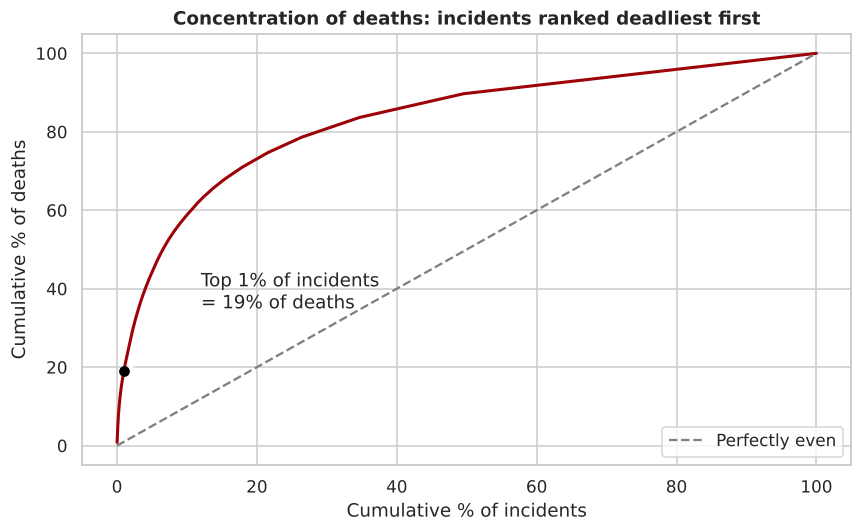

In [37]:
s = df["deaths"].sort_values(ascending=False).reset_index(drop=True)
cum_deaths = s.cumsum() / s.sum() * 100
cum_inc = np.arange(1, len(s) + 1) / len(s) * 100
idx = int(len(s) * 0.01) - 1

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(cum_inc, cum_deaths, color="#9d0208", lw=2)
ax.plot([0, 100], [0, 100], color="grey", ls="--", label="Perfectly even")
ax.scatter([cum_inc[idx]], [cum_deaths[idx]], color="black", zorder=5)
ax.annotate(f"Top 1% of incidents\n= {cum_deaths[idx]:.0f}% of deaths", (cum_inc[idx], cum_deaths[idx]),
            xytext=(12, 35), arrowprops=dict(arrowstyle="->"))
ax.set_title("Concentration of deaths: incidents ranked deadliest first")
ax.set_xlabel("Cumulative % of incidents")
ax.set_ylabel("Cumulative % of deaths")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 5. Findings and Recommendations

### Key findings

| # | Finding | Evidence |
|---|---|---|
| 1 | **Deaths are heavily concentrated in a few states.** Borno, Niger, Zamfara, Benue and Katsina hold 45% of all recorded deaths. | 23,965 of 52,732 deaths |
| 2 | **Incident count and deadliness are different things.** Lagos has the most incidents (871) but about 1.7 deaths each. Borno has fewer incidents (545) but 16.6 deaths each. | Section 3.2, charts 4.2 and 4.3 |
| 3 | **The north accounts for about 78% of deaths.** North West (27.5%), North Central (26.1%) and North East (24.4%) each outweigh any southern zone (6% to 9% each). | Section 3.4, chart 4.8 |
| 4 | **Security operations, banditry and road accidents cause the most deaths.** Together they account for roughly 57% of deaths. Road accidents are the leading non-conflict cause (7,068 deaths). | Section 3.3, chart 4.4 |
| 5 | **A small number of events drive the totals.** The 101 incidents with 50 or more deaths (under 1% of incidents) account for about 19% of all deaths. The largest was the 2025 Niger flooding (440). | Section 3.6, chart 4.10 |
| 6 | **Incidents are flat, but each one is getting deadlier.** Incidents stayed near 2,600 a year in 2023 to 2025, while deaths rose from 11,893 to 12,999 (4.6 to 5.1 deaths per incident). | Section 3.5, chart 4.5 |
| 7 | **There is a seasonal pattern.** April to June is the deadliest period and December the lightest. | Chart 4.6 |
| 8 | **The South West is a different problem.** Its deaths are mainly road accidents and cult violence, not armed conflict. | Charts 4.8 and 4.9 |

### Recommendations

1. **Focus security and humanitarian resources on the north-east and north-west hotspots.** Borno, Zamfara, Katsina and Niger combine high totals with high deaths per incident, so each incident there is costly. Prioritise protection of civilians and rapid response in these states.
2. **Treat road safety as a priority in the South West and around the FCT.** Ogun, Lagos and the FCT have the most road-accident records. Road accidents are the largest source of non-conflict deaths, so enforcement, road repairs and vehicle checks on high-volume routes would save many lives.
3. **Build flood and disaster readiness before the rainy season.** Floods and natural disasters have a high average toll (7.5 deaths) and include the single deadliest event in the data. Early-warning systems and evacuation plans in flood-prone states such as Niger should be in place before April.
4. **Plan seasonally.** April to June is the peak, so agencies should schedule staffing, patrols and emergency stock ahead of it.
5. **Prepare for mass-casualty events.** Because fewer than 1% of incidents cause almost a fifth of deaths, emergency services need surge capacity (ambulances, blood supply, hospital coordination) and not only capacity for typical incidents.
6. **Improve the data itself.** The dataset has no state, incident-type, victim-type or source columns. Adding these (and separating civilian deaths from combatant deaths) would make future analysis much more reliable.

### Limitations

- **The data is based on reported incidents** (media-style titles), so under-reported areas may look safer than they are.
- **Deaths only:** non-fatal incidents and injuries are not recorded.
- **Partial years:** 2022 (from 17 June) and 2026 (to 14 July) are not full years, so trends use 2023 to 2025 only.
- **Category assignment is keyword-based.** About 19% of rows fall in "Other", and the "Military operation" category includes deaths of suspected militants killed by security forces.
- **Minor data fixes:** 14 reversed dates were swapped and 12 rows have an unknown state. This is too few to change any conclusion.